# Weekly project

Today you are going to implement the last parts of the algorithm you started on monday. For reference you can see it below.

![title](algorithm_3.png)

It is a good idea to follow and track the steps in the algorithm in the below implementation. Only take one step at a time.

Once you have the algorithm up and running you can try with a larger dataset to see if your algorithm is able to maintain good accurracy over a longer distance. The larger dataset can be found here:
[Left images](https://dtudk-my.sharepoint.com/:u:/g/personal/evanb_dtu_dk/EQu8kmGBDDROtGJ7IkZB2tQBJrxmgY9t8LVM_JuEi83TYw)
[Right images](https://dtudk-my.sharepoint.com/:u:/g/personal/evanb_dtu_dk/EcKI_zrXTvpMulizidCZm4oBLJcQ_LTV9Zs6oQFF74JTRQ)

In [1]:
import numpy as np
import cv2 as cv2
import glob
import matplotlib.pyplot as plt

def getK():
    return np.array([[7.188560e+02, 0.000000e+00, 6.071928e+02],
                     [0, 7.188560e+02, 1.852157e+02],
                     [0, 0, 1]])

def getTruePose():
    file = '00.txt'
    return np.genfromtxt(file, delimiter=' ', dtype=None)

<details>
  <summary>tips:</summary>

- [Feature Matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)
- To get the keypoint of a certain match do: ```kp1[match.queryIdx].pt``` and ```kp2[match.trainIdx].pt```

In [2]:
def extract_keypoints_sift(img1, img2, K, baseline, refPoints=None):
    """
    Use SIFT to detect keypoints and compute descriptors in both images,
    and find matches between them using knnMatch with k=2
    """
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    """
    Get the best keypoints by applying the Lowes ratio test
    """
    match_points1 = []
    match_points2 = []
    for m, n in matches:
        # keep the match only if it is clearly better than the second best
        if m.distance < 0.75 * n.distance:
            match_points1.append(kp1[m.queryIdx].pt)
            match_points2.append(kp2[m.trainIdx].pt)

    # Transform best keypoints to nparray
    p1 = np.array(match_points1).astype('float32')
    p2 = np.array(match_points2).astype('float32')

    # challenge: remove new points that are too close to the old points we already track
    if refPoints is not None:
        keep = removeDuplicate(p1.copy(), refPoints)
        p1 = p1[keep]
        p2 = p2[keep]

    ##### ############# ##########
    ##### Do Triangulation #######
    ##### ########################
    # project the feature points to 3D with triangulation
    # projection matrix for Left and Right Image
    M_left = K.dot(np.hstack((np.eye(3), np.zeros((3, 1)))))
    M_rght = K.dot(np.hstack((np.eye(3), np.array([[-baseline, 0, 0]]).T)))

    p1_flip = np.vstack((p1.T, np.ones((1, p1.shape[0]))))
    p2_flip = np.vstack((p2.T, np.ones((1, p2.shape[0]))))

    P = cv2.triangulatePoints(M_left, M_rght, p1_flip[:2], p2_flip[:2])

    # Normalize homogeneous coordinates (P->Nx4  [N,4] is the normalizer/scale)
    P = P / P[3]
    land_points = P[:3]

    return land_points.T, p1

In [3]:
def featureTracking(prev_img, next_img, prev_points, world_points):
    """
    Use OpenCV to find the prev_points from the prev_img in the next_img
    Remember to remove points that could not be found from prev_points, next_points, and world_points
    hint: status == 1
    """
    params = dict(winSize=(21, 21),
                 maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

    next_points, status, _ = cv2.calcOpticalFlowPyrLK(prev_img, next_img, prev_points, None, **params)

    # keep only the points that were found, in all three arrays so they stay matched
    found = status.ravel() == 1
    world_points = world_points[found]
    prev_points = prev_points[found]
    next_points = next_points[found]

    return world_points, prev_points, next_points

In [4]:
def playImageSequence(l_img_paths, r_img_paths, K, accumulate=False, save_name='trajectory.png', verbose=True):
    baseline = 0.54
    left_img = cv2.imread(l_img_paths[0], 0)
    right_img = cv2.imread(r_img_paths[0], 0)
    cv2.setRNGSeed(0)  # so RANSAC gives the same result every run

    ##### ################################# #######
    ##### Get 3D points Using Triangulation #######
    ##### #########################################
    """
    Implement step 1.2 and 1.3
    Store the features in 'reference_2D' and the 3D points (landmarks) in 'landmark_3D'
    hint: use 'extract_keypoints_sift' above
    """
    # the first camera is the world frame, so these 3D points are already in world coordinates
    landmark_3D, reference_2D = extract_keypoints_sift(left_img, right_img, K, baseline)

    # reference
    reference_img = left_img

    # Groundtruth for plot
    truePose = getTruePose()
    traj = np.zeros((600, 600, 3), dtype=np.uint8)
    maxError = 0
    est_positions = []

    for i in range(1, len(l_img_paths)):
        if verbose:
            print('image: ', i)
        curImage = cv2.imread(l_img_paths[i], 0)
        curImage_R = cv2.imread(r_img_paths[i], 0)

        ##### ############################################################# #######
        ##### Calculate 2D and 3D feature correspndances in t=T-1, and t=T  #######
        ##### #####################################################################
        """
        Implement step 2.2)
        Remember this is a part of a loop, so the initial features are already
        provided in step 1)-1.3) outside the loop in 'reference_2D' and 'landmark_3D'
        """
        landmark_3D, reference_2D, tracked_2Dpoints = featureTracking(reference_img,
                                                                      curImage,
                                                                      reference_2D,
                                                                      landmark_3D)

        ##### ####################################### #######
        ##### Calculate relative pose using PNPRansac #######
        ##### ###############################################
        """
        Implement step 2.3)
        """
        _, rvec, tvec, inliers = cv2.solvePnPRansac(landmark_3D, tracked_2Dpoints, K, None)

        if accumulate:
            # challenge: keep the old points that RANSAC accepted and that are in front of the camera
            R_cam, _ = cv2.Rodrigues(rvec)
            z_cam = (R_cam.dot(landmark_3D.T) + tvec)[2]  # depth of every 3D point in the current camera
            keep = np.zeros(len(landmark_3D), dtype=bool)
            keep[inliers.ravel()] = True
            keep = keep & (z_cam > 0)
            old_3D = landmark_3D[keep]
            old_2D = tracked_2Dpoints[keep].reshape(-1, 2)

        ##### ####################################################### #######
        ##### Get Pose and Tranformation Matrix in world coordionates #######
        ##### ###############################################################
        rot, _ = cv2.Rodrigues(rvec)
        tvec = -rot.T.dot(tvec)  # coordinate transformation, from camera to world. What is the XYZ of the camera wrt World
        inv_transform = np.hstack((rot.T, tvec))  # inverse transform. A tranform projecting points from the camera frame to the world frame

        ##### ################################# #######
        ##### Get 3D points Using Triangulation #######
        ##### #########################################
        # re-obtain the 3D points.
        # hint: use 'extract_keypoints_sift' again
        """
        Implement step 2.4)
        """
        # new stereo points in the current frame, these are in the current camera frame
        if accumulate:
            landmark_3D_new, reference_2D_new = extract_keypoints_sift(curImage, curImage_R, K, baseline, old_2D)
        else:
            landmark_3D_new, reference_2D_new = extract_keypoints_sift(curImage, curImage_R, K, baseline)

        #Project the points from camera to world coordinates
        reference_2D = reference_2D_new.astype('float32')
        landmark_3D = inv_transform.dot(np.vstack((landmark_3D_new.T, np.ones((1, landmark_3D_new.shape[0])))))
        landmark_3D = landmark_3D.T

        if accumulate:
            # add the old points to the new ones, 2D and 3D in the same order
            reference_2D = np.vstack((old_2D, reference_2D))
            landmark_3D = np.vstack((old_3D, landmark_3D))

        ##### ####################### #######
        ##### Done, Next image please #######
        ##### ###############################
        reference_img = curImage

        ##### ################################## #######
        ##### START OF Print and visualize stuff #######
        ##### ##########################################
        # draw images
        draw_x, draw_y = int(tvec[0, 0]) + 300, 600-(int(tvec[2, 0]) + 100)
        true_x, true_y = int(truePose[i][3]) + 300, 600-(int(truePose[i][11]) + 100)

        curError = np.sqrt(
            (tvec[0] - truePose[i][3]) ** 2 +
            (tvec[1] - truePose[i][7]) ** 2 +
            (tvec[2] - truePose[i][11]) ** 2)

        if (curError > maxError):
            maxError = curError

        if verbose:
            print(tvec[0],tvec[1],tvec[2], rvec[0], rvec[1], rvec[2])
            print([truePose[i][3], truePose[i][7], truePose[i][11]])
        elif i % 200 == 0:
            print(f'image {i}, error {curError[0]:.2f} m')  # short progress for long runs
        est_positions.append(tvec.ravel())

        text = "Coordinates: x ={0:02f}m y = {1:02f}m z = {2:02f}m".format(float(tvec[0, 0]), float(tvec[1, 0]),
                                                                           float(tvec[2, 0]))
        cv2.circle(traj, (draw_x, draw_y), 1, (0, 0, 255), 2)
        cv2.circle(traj, (true_x, true_y), 1, (255, 0, 0), 2)
        cv2.rectangle(traj, (10, 30), (550, 50), (0, 0, 0), cv2.FILLED)
        cv2.putText(traj, text, (10, 50), cv2.FONT_HERSHEY_PLAIN, 1, (255, 255, 255), 1, 8)

        h1, w1 = traj.shape[:2]
        h2, w2 = curImage.shape[:2]
        vis = np.zeros((max(h1, h2), w1 + w2, 3), np.uint8)
        vis[:h1, :w1, :3] = traj
        vis[:h2, w1:w1 + w2, :3] = np.dstack((np.dstack((curImage,curImage)),curImage))

        cv2.imshow("Trajectory", vis)
        k = cv2.waitKey(1) & 0xFF
        if k == 27: break


    cv2.waitKey(0)
    cv2.destroyAllWindows()
    cv2.waitKey(1)  # needed on Mac so the window really closes
    print('Maximum Error: ', maxError)

    # save the last frame of the trajectory window so it can be shown in the notebook
    cv2.imwrite(save_name, vis)
    true_positions = truePose[1:len(est_positions) + 1][:, [3, 7, 11]]
    return np.array(est_positions), true_positions, float(np.squeeze(maxError))
    ##### ################################ #######
    ##### END OF Print and visualize stuff #######
    ##### ########################################

In [5]:
# Load image paths
left_img_paths = sorted(glob.glob('data/left/*.png'))
right_img_paths = sorted(glob.glob('data/right/*.png'))

K = getK()

# a window shows the trajectory live, press any key at the end to close it
est, true, max_err = playImageSequence(left_img_paths, right_img_paths, K, save_name='trajectory_base.png')

image:  1
[-0.00227839] [-0.00703923] [0.67547523] [-0.00217426] [0.00334329] [-0.00261036]
[np.float64(-0.04690294), np.float64(-0.02839928), np.float64(0.8586941)]
image:  2
[-0.01421218] [-0.01295033] [1.37229752] [-0.00388046] [0.0073793] [-0.00082553]
[np.float64(-0.09374345), np.float64(-0.05676064), np.float64(1.716275)]
image:  3
[-0.032999] [-0.01979139] [2.0858905] [-0.00542574] [0.0111697] [-0.00062243]
[np.float64(-0.1406429), np.float64(-0.08515762), np.float64(2.574964)]
image:  4
[-0.05167475] [-0.03353071] [2.81642388] [-0.00589889] [0.0160554] [0.0010948]
[np.float64(-0.1874858), np.float64(-0.1135202), np.float64(3.432648)]
image:  5
[-0.06795923] [-0.04547949] [3.55923969] [-0.0060917] [0.02061187] [7.70926288e-05]
[np.float64(-0.2343818), np.float64(-0.141915), np.float64(4.291335)]
image:  6
[-0.09344165] [-0.05798521] [4.31460794] [-0.00739334] [0.02516383] [0.00216645]
[np.float64(-0.2812195), np.float64(-0.1702743), np.float64(5.148987)]
image:  7
[-0.12680478] 

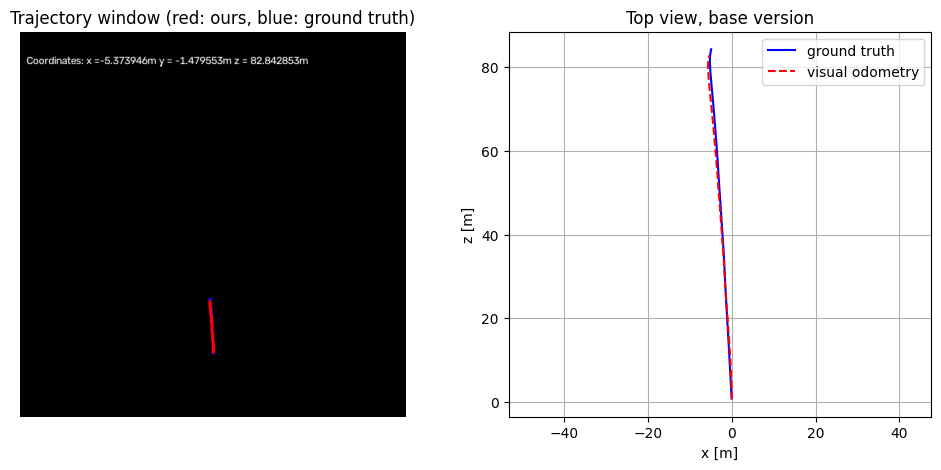

distance driven: 83.7 m
final error: 2.11 m, max error: 2.15 m


In [6]:
def plot_trajectory(img_file, est, true, title):
    # left: the screenshot of the trajectory window, right: top view (x, z) in metres
    img = cv2.imread(img_file)[:, :600, ::-1]  # only the trajectory part, BGR to RGB

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img)
    axes[0].set_title('Trajectory window (red: ours, blue: ground truth)')
    axes[0].axis('off')

    axes[1].plot(true[:, 0], true[:, 2], 'b', label='ground truth')
    axes[1].plot(est[:, 0], est[:, 2], 'r--', label='visual odometry')
    axes[1].set_xlabel('x [m]')
    axes[1].set_ylabel('z [m]')
    axes[1].axis('equal')
    axes[1].grid(True)
    axes[1].legend()
    axes[1].set_title(title)
    plt.show()

    err = np.linalg.norm(est - true, axis=1)
    path_length = np.sum(np.linalg.norm(np.diff(true, axis=0), axis=1))
    print(f'distance driven: {path_length:.1f} m')
    print(f'final error: {err[-1]:.2f} m, max error: {err.max():.2f} m')

plot_trajectory('trajectory_base.png', est, true, 'Top view, base version')

## Results

The estimated path follows the ground truth well, the car drives almost straight forward for about 84 m. The error grows over time, because every step is estimated relative to the previous one, so small errors add up (drift). At the end we are about 1.5 m off in height (y) and 1.5 m short in the driving direction (z), while x is quite good.

# Challenge 
The current implementation only uses features computed at the current timestep. However, as we process more images we potentially have a lot of features from previous timesteps that are still valid. The challenge is to expand the `extract_keypoints_surf(..., refPoints)` function by giving it old reference points. You should then combine your freshly computed features with the old features and remove all duplicates. This requires you to keep track of old features and 3D points.

Hint 1: The following function `removeDuplicate` can be used for removing duplicates.

Hint 2: you are not interested in points that are behind you, so remember to remove points that are negative in the direction you move.

In [7]:
def removeDuplicate(queryPoints, refPoints, radius=5):
    # remove duplicate points from new query points,
    for i in range(len(queryPoints)):
        query = queryPoints[i]
        xliml, xlimh = query[0] - radius, query[0] + radius
        yliml, ylimh = query[1] - radius, query[1] + radius
        inside_x_lim_mask = (refPoints[:, 0] > xliml) & (refPoints[:, 0] < xlimh)
        curr_kps_in_x_lim = refPoints[inside_x_lim_mask]

        if curr_kps_in_x_lim.shape[0] != 0:
            inside_y_lim_mask = (curr_kps_in_x_lim[:, 1] > yliml) & (curr_kps_in_x_lim[:, 1] < ylimh)
            curr_kps_in_x_lim_and_y_lim = curr_kps_in_x_lim[inside_y_lim_mask, :]
            if curr_kps_in_x_lim_and_y_lim.shape[0] != 0:
                queryPoints[i] = np.array([0, 0])
    return (queryPoints[:, 0] != 0)

### Challenge: features from multiple frames

In the base version we throw away all points at the end of every loop and only use the new stereo matches. Here we keep the old points that are still tracked and add the new ones:

1. After PnP we keep only the old points that RANSAC marked as inliers and that are in front of the camera (positive depth in the current camera frame).
2. New stereo points that are within 5 pixels of an old point are removed with removeDuplicate, so we do not get the same point twice.
3. Old and new points are stacked in the same order for 2D and 3D, so they stay matched.

In [8]:
est_acc, true_acc, max_err_acc = playImageSequence(left_img_paths, right_img_paths, K,
                                                   accumulate=True, save_name='trajectory_challenge.png')

image:  1
[-0.00227839] [-0.00703923] [0.67547523] [-0.00217426] [0.00334329] [-0.00261036]
[np.float64(-0.04690294), np.float64(-0.02839928), np.float64(0.8586941)]
image:  2
[-0.01204555] [-0.01211523] [1.37665978] [-0.00375609] [0.00759278] [-0.00109661]
[np.float64(-0.09374345), np.float64(-0.05676064), np.float64(1.716275)]
image:  3
[-0.03161761] [-0.01811958] [2.08734741] [-0.00519484] [0.01145246] [-0.00100673]
[np.float64(-0.1406429), np.float64(-0.08515762), np.float64(2.574964)]
image:  4
[-0.05079152] [-0.0246479] [2.82419156] [-0.00586082] [0.01640811] [0.00032815]
[np.float64(-0.1874858), np.float64(-0.1135202), np.float64(3.432648)]
image:  5
[-0.06664901] [-0.03612155] [3.5575349] [-0.0059817] [0.02088156] [-0.00075528]
[np.float64(-0.2343818), np.float64(-0.141915), np.float64(4.291335)]
image:  6
[-0.09143565] [-0.04853881] [4.30886637] [-0.00711067] [0.025512] [0.00116764]
[np.float64(-0.2812195), np.float64(-0.1702743), np.float64(5.148987)]
image:  7
[-0.12561589] 

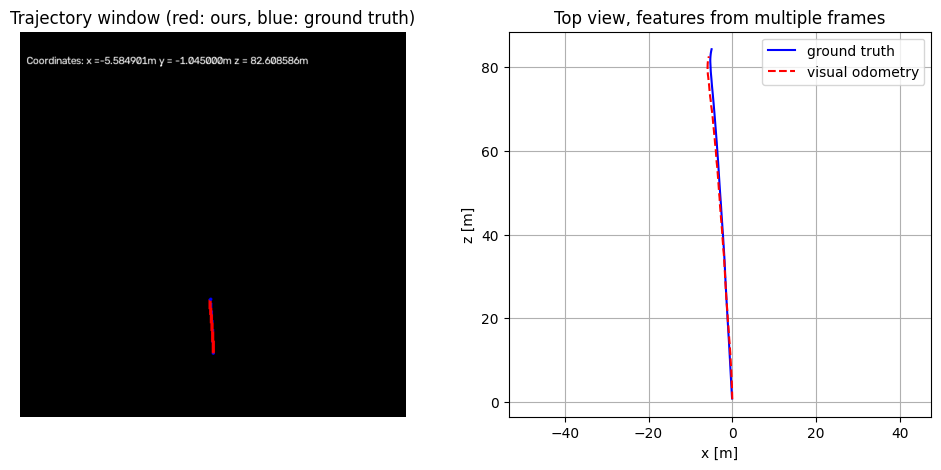

distance driven: 83.7 m
final error: 2.62 m, max error: 2.64 m


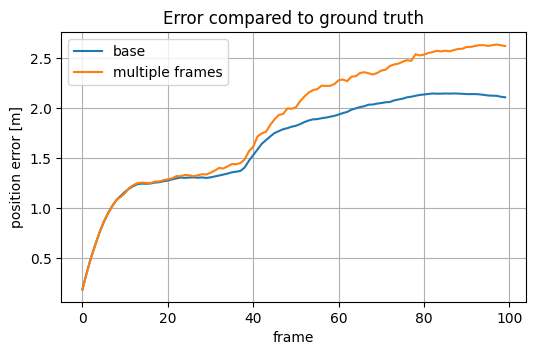

In [9]:
plot_trajectory('trajectory_challenge.png', est_acc, true_acc, 'Top view, features from multiple frames')

err_base = np.linalg.norm(est - true, axis=1)
err_acc = np.linalg.norm(est_acc - true_acc, axis=1)

plt.figure(figsize=(6, 3.5))
plt.plot(err_base, label='base')
plt.plot(err_acc, label='multiple frames')
plt.xlabel('frame')
plt.ylabel('position error [m]')
plt.grid(True)
plt.legend()
plt.title('Error compared to ground truth')
plt.show()

### Challenge: larger dataset

Now we run the same code on the first 1771 frames of the KITTI sequence, which is about 1.3 km with several turns. We run both the base version and the version with features from multiple frames. To keep the output short, we only print the error every 200 frames.

In [10]:
left_big = sorted(glob.glob('data/kitti_data_left_first_1771/*.png'))
right_big = sorted(glob.glob('data/kitti_data_right_first_1771/*.png'))
print('number of frames:', len(left_big))

est_big, true_big, _ = playImageSequence(left_big, right_big, K, save_name='trajectory_large_base.png', verbose=False)

number of frames: 1771
image 200, error 1.79 m
image 400, error 1.97 m
image 600, error 9.17 m
image 800, error 6.21 m
image 1000, error 26.18 m
image 1200, error 38.78 m
image 1400, error 27.39 m
image 1600, error 39.59 m
Maximum Error:  [47.60493608]


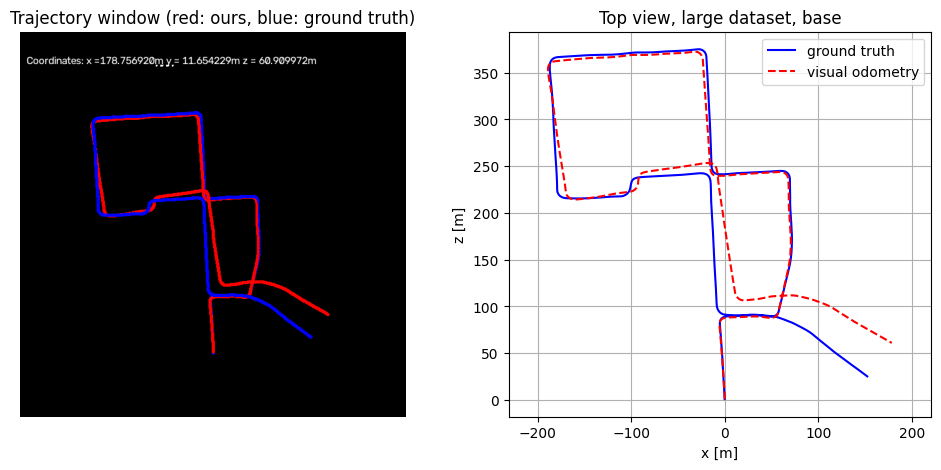

distance driven: 1323.0 m
final error: 47.60 m, max error: 47.60 m


In [11]:
plot_trajectory('trajectory_large_base.png', est_big, true_big, 'Top view, large dataset, base')

In [12]:
est_big_acc, true_big_acc, _ = playImageSequence(left_big, right_big, K, accumulate=True,
                                                 save_name='trajectory_large_challenge.png', verbose=False)

image 200, error 2.15 m
image 400, error 7.06 m
image 600, error 8.14 m
image 800, error 12.30 m
image 1000, error 12.97 m
image 1200, error 7.48 m
image 1400, error 5.96 m
image 1600, error 5.48 m
Maximum Error:  [15.21612704]


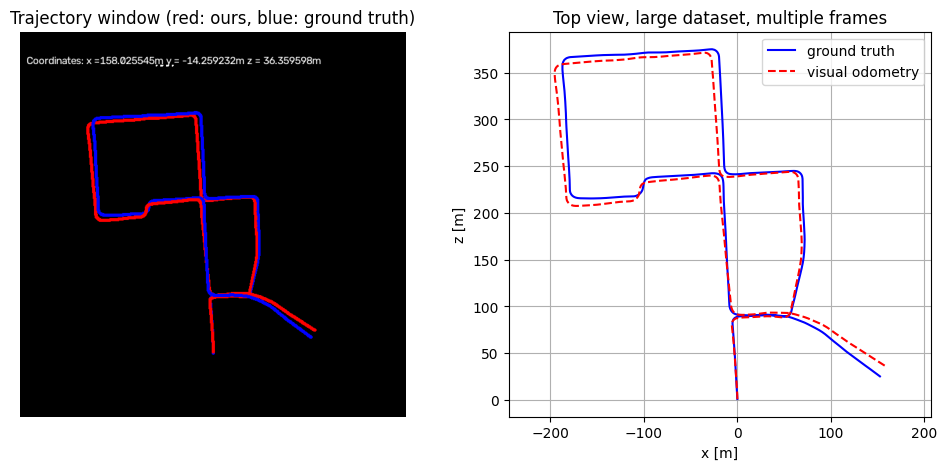

distance driven: 1323.0 m
final error: 15.22 m, max error: 15.22 m


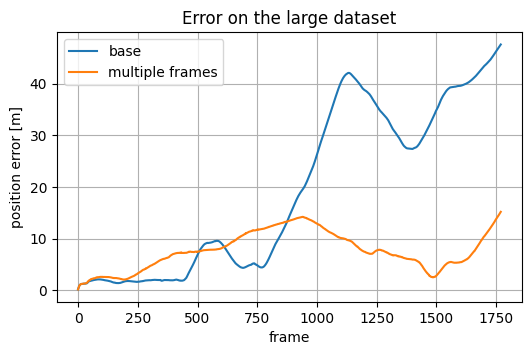

In [13]:
plot_trajectory('trajectory_large_challenge.png', est_big_acc, true_big_acc, 'Top view, large dataset, multiple frames')

plt.figure(figsize=(6, 3.5))
plt.plot(np.linalg.norm(est_big - true_big, axis=1), label='base')
plt.plot(np.linalg.norm(est_big_acc - true_big_acc, axis=1), label='multiple frames')
plt.xlabel('frame')
plt.ylabel('position error [m]')
plt.grid(True)
plt.legend()
plt.title('Error on the large dataset')
plt.show()

## Final comments

On the 100 frames the visual odometry works well. The final error is about 2.1 m after 84 m (2.5%), and the path has the right shape. The error comes from drift, every pose is estimated from the one before, so small errors add up.

Keeping points from earlier frames did not help on the short sequence, the final error was about 2.6 m. On the large dataset (about 1.3 km) it helped a lot:

| | final error | error / distance |
|---|---|---|
| base | 47.6 m | 3.6% |
| multiple frames | 15.2 m | 1.2% |

In the base version the error grows fast between frame 800 and 1000. In the top view we see that after one of the turns the path goes in a slightly wrong direction, and this error stays for the rest of the run. With the old points we have more points that are tracked over several frames, which probably makes the rotation estimate more stable in the turns. Both versions still drift, because nothing corrects the path when the car comes back to a place it has seen before.

Note: We used generative AI to help with the code and comments.